# Analisis de desempeño de RappiPlus con insight actionables para el siguiente año

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajaron con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. Analizar si el negocio es rentable (revenue, costos y profit)  

3. Entender dónde se pierden los usuarios (funnel de conversión)  

4. Evaluar si los usuarios regresan (retención por cohortes)  

5. Validar si los cambios generan impacto (test estadístico)  

6. Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')

In [3]:
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
# explorar datasets
def exploracionInicial(df):
    print(df.info())
    print(df.shape)
exploracionInicial(orders)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB
None
(25100, 12)


In [5]:
catalog

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"
5,Sneakers-Urban-42,Moda,17.21,Greene-Smith
6,Jacket-Winter-M,Moda,189.31,Mcmillan-Rhodes


In [6]:
exploracionInicial(catalog)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes
None
(7, 4)


In [7]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [8]:
exploracionInicial(marketing)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB
None
(1620, 5)


---

### Revisión y calidad de datos
---

Empezamos analisando Fechas

In [9]:
print(orders['fecha_hora_pedido'].describe())
print(marketing['fecha'].describe())

count          25100
unique           181
top       2025-06-25
freq             176
Name: fecha_hora_pedido, dtype: object
count           1620
unique           180
top       2025-04-30
freq               9
Name: fecha, dtype: object


In [10]:
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'],errors="coerce")
marketing['fecha']= pd.to_datetime(marketing['fecha'],errors="coerce")

In [11]:
print(orders['fecha_hora_pedido'].describe())
print(marketing['fecha'].describe())

count                   25100
unique                    181
top       2025-06-25 00:00:00
freq                      176
first     2025-01-01 00:00:00
last      2025-06-30 00:00:00
Name: fecha_hora_pedido, dtype: object
count                    1620
unique                    180
top       2025-06-25 00:00:00
freq                        9
first     2025-01-01 00:00:00
last      2025-06-29 00:00:00
Name: fecha, dtype: object


Hacemos un analisis general de los nulos en los diferentes datasets

In [12]:
print("cantidad de nulos en orders: ", orders.isna().sum().sum())
print("cantidad de nulos en catalog: ", catalog.isna().sum().sum())
print("cantidad de nulos en marketing: ", marketing.isna().sum().sum())

cantidad de nulos en orders:  610
cantidad de nulos en catalog:  0
cantidad de nulos en marketing:  101


In [13]:
print("cantidad de nulos en orders desglosado: ", orders.isna().sum())
print("cantidad de nulos en catalog desglosado: ", catalog.isna().sum())
print("cantidad de nulos en marketing desglosado: ", marketing.isna().sum())

cantidad de nulos en orders desglosado:  id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64
cantidad de nulos en catalog desglosado:  nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64
cantidad de nulos en marketing desglosado:  fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64


Ya que monto total es la que tiene su registros completos es la que vamos a utilizar de referencia para futuras ecuaciones

In [14]:
variables_numericas=['cantidad','precio_unitario','monto_descuento','monto_total']
def clean_number(df,arr_col):
    for col in arr_col:
        df.loc[df[col]<=0, col]= np.NaN
clean_number(orders,variables_numericas)
        

In [15]:
orders[orders['monto_total'].isna()]
orders = orders.dropna(subset=["monto_total"]).reset_index(drop=True)

In [16]:
orders[orders['categoria_producto'].isna()]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
44,order_44,user_2899,2025-02-22,Colombia,desktop,NaN,NaN,NaN,1.0,318.38,5.0,313.38
45,order_45,user_6196,2025-02-10,Mexico,mobile,NaN,NaN,NaN,2.0,354.06,10.0,698.12
46,order_46,user_5815,2025-04-24,Mexico,mobile,NaN,NaN,NaN,1.0,359.31,10.0,349.31
47,order_47,user_406,2025-05-08,Colombia,mobile,NaN,NaN,NaN,2.0,476.78,NaN,953.56
48,order_48,user_6187,2025-01-26,Colombia,desktop,NaN,NaN,NaN,2.0,137.96,NaN,275.93
...,...,...,...,...,...,...,...,...,...,...,...,...
119,order_119,user_4494,2025-01-16,Argentina,mobile,social,Sneakers-Urban-42,NaN,NaN,NaN,NaN,196.45
120,order_120,user_4220,2025-02-03,Mexico,mobile,organic,Sneakers-Urban-42,NaN,NaN,NaN,NaN,355.15
121,order_121,user_2114,2025-04-25,colombia,desktop,social,Sneakers-Urban-42,NaN,NaN,NaN,NaN,724.38
122,order_122,user_2546,2025-06-23,Mexico,desktop,paid_search,Sneakers-Urban-42,NaN,NaN,NaN,NaN,469.20


In [17]:
def fillNaColRef(df_orders,df_catalog,col_origen,col_destino,map_index,destino_index):
    mapeo_info = df_catalog.set_index(map_index)[col_origen]
    info_de_catalog= df_orders[destino_index].map(mapeo_info)
    df_orders[col_destino] = df_orders[col_destino].fillna(info_de_catalog)

fillNaColRef(orders,catalog,'categoria_producto','categoria_producto','nombre_producto','nombre_producto')

orders[orders['categoria_producto'].isna()]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
44,order_44,user_2899,2025-02-22,Colombia,desktop,NaN,NaN,NaN,1.0,318.38,5.0,313.38
45,order_45,user_6196,2025-02-10,Mexico,mobile,NaN,NaN,NaN,2.0,354.06,10.0,698.12
46,order_46,user_5815,2025-04-24,Mexico,mobile,NaN,NaN,NaN,1.0,359.31,10.0,349.31
47,order_47,user_406,2025-05-08,Colombia,mobile,NaN,NaN,NaN,2.0,476.78,NaN,953.56
48,order_48,user_6187,2025-01-26,Colombia,desktop,NaN,NaN,NaN,2.0,137.96,NaN,275.93
49,order_49,user_7225,2025-04-04,Argentina,desktop,NaN,NaN,NaN,2.0,433.76,NaN,867.53
50,order_50,user_1840,2025-02-05,Mexico,desktop,NaN,NaN,NaN,1.0,495.38,5.0,490.38
51,order_51,user_5998,2025-02-21,Mexico,desktop,NaN,NaN,NaN,2.0,382.94,NaN,765.89
52,order_52,user_5679,2025-04-17,Argentina,mobile,NaN,NaN,NaN,2.0,415.01,NaN,830.01
53,order_53,user_5936,2025-01-02,Argentina,desktop,NaN,NaN,NaN,2.0,236.49,NaN,472.98


In [18]:
columnas_categoricas = ['pais','dispositivo']
def fillNaCategorico(df,col):
    moda_categorica = df[col].describe()['top']
    df[col] = df[col].fillna(moda_categorica)
fillNaCategorico(orders,'pais')
fillNaCategorico(orders,'dispositivo')
fillNaCategorico(orders,'nombre_producto')
fillNaCategorico(orders,'fuente_referencia')
fillNaColRef(orders,catalog,'categoria_producto','categoria_producto','nombre_producto','nombre_producto')
orders[orders['categoria_producto'].isna()]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total


Empezamos a hacer calculos en nuevas columnas para identificar el comportamiento de los calculos basados en otros registros

In [19]:
print("cantidad de nulos en orders desglosado: ", orders.isna().sum())

cantidad de nulos en orders desglosado:  id_pedido                 0
id_usuario                0
fecha_hora_pedido         0
pais                      0
dispositivo               0
fuente_referencia         0
nombre_producto           0
categoria_producto        0
cantidad                 50
precio_unitario          50
monto_descuento       12600
monto_total               0
dtype: int64


In [20]:
orders['descuento_calculado'] = (orders['precio_unitario'] * orders['cantidad'] - orders['monto_total']).round().abs()
orders[['nombre_producto','cantidad','precio_unitario','monto_descuento','descuento_calculado','monto_total']].head(20)
orders['cantidad_calculada'] = ((orders['monto_total']) / orders['precio_unitario']).round()
orders[orders['descuento_calculado'].isna()]
orders['descuento_calculado'] = (orders['precio_unitario'] * orders['cantidad_calculada'] - orders['monto_total']).round().abs()
orders[orders['cantidad_calculada'].isna()]
orders['precio_unitario_calculado'] = (orders['monto_total'] + orders['descuento_calculado'])/orders['cantidad_calculada']
orders[['nombre_producto','cantidad','precio_unitario','precio_unitario_calculado','monto_descuento','descuento_calculado','monto_total']].head(20)

,nombre_producto,cantidad,precio_unitario,precio_unitario_calculado,monto_descuento,descuento_calculado,monto_total
0,Jacket-Winter-M,2.0,332.69,332.685,NaN,0.0,665.37
1,Tablet-Standard-64GB,1.0,176.86,176.860,5.0,5.0,171.86
2,Blender-XL-Red,2.0,102.99,102.995,10.0,10.0,195.99
3,Tablet-Standard-64GB,1.0,257.87,257.870,15.0,15.0,242.87
4,Blender-XL-Red,1.0,336.28,336.280,NaN,0.0,336.28
5,Tablet-Standard-64GB,1.0,179.34,179.340,NaN,0.0,179.34
6,Blender-XL-Red,2.0,163.59,163.595,NaN,0.0,327.19
7,Tablet-Standard-64GB,2.0,373.68,373.675,NaN,0.0,747.35
8,Laptop-Gaming-16GB,2.0,477.27,477.270,5.0,5.0,949.54
9,Sneakers-Urban-42,1.0,339.30,339.300,5.0,5.0,334.30


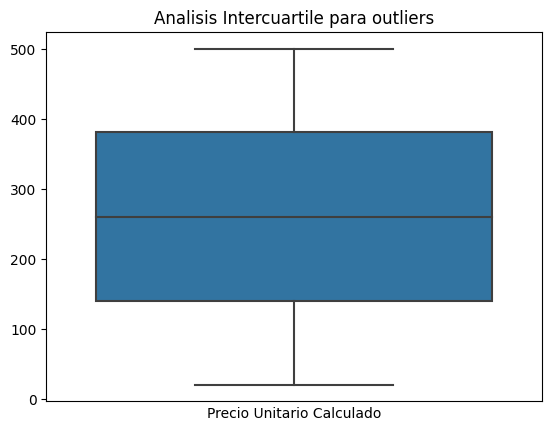

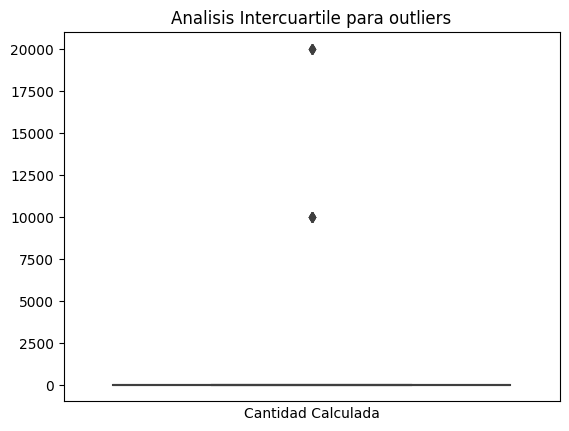

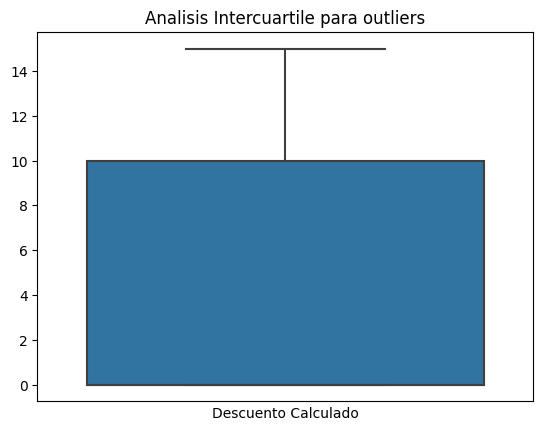

In [21]:
def analisisInterquartile(df,col,titulo,labelx):
    ax = sns.boxplot(data=df[col])
    ax.set_xlabel(labelx)
    ax.set_xticks([])
    plt.title(titulo)
    plt.show()
analisisInterquartile(orders,'precio_unitario_calculado','Analisis Intercuartile para outliers','Precio Unitario Calculado')
analisisInterquartile(orders,'cantidad_calculada','Analisis Intercuartile para outliers','Cantidad Calculada')
analisisInterquartile(orders,'descuento_calculado','Analisis Intercuartile para outliers','Descuento Calculado')

In [22]:
orders.loc[orders['cantidad_calculada']>=1000, 'cantidad_calculada']= np.NaN
orders = orders.dropna(subset=["cantidad_calculada"]).reset_index(drop=True)

Exploramos mediante bloxplot los outliers de nuestras columnas calculadas

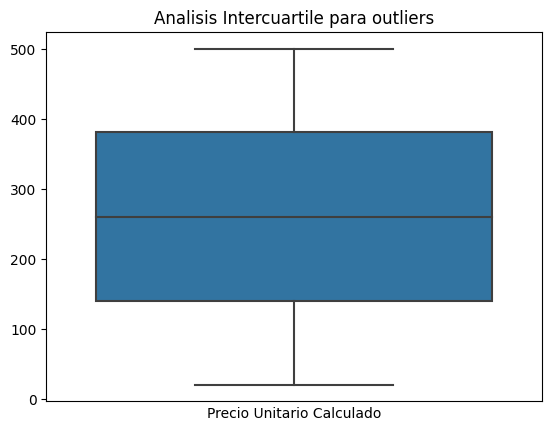

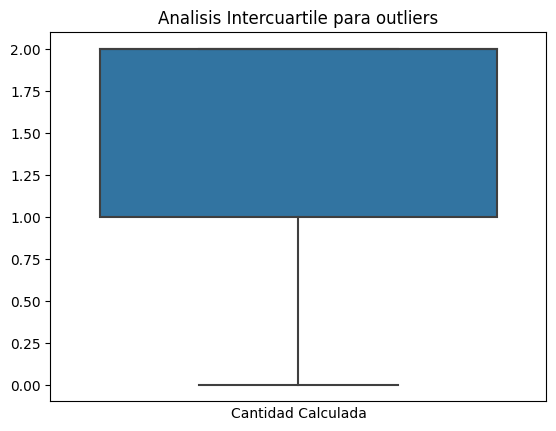

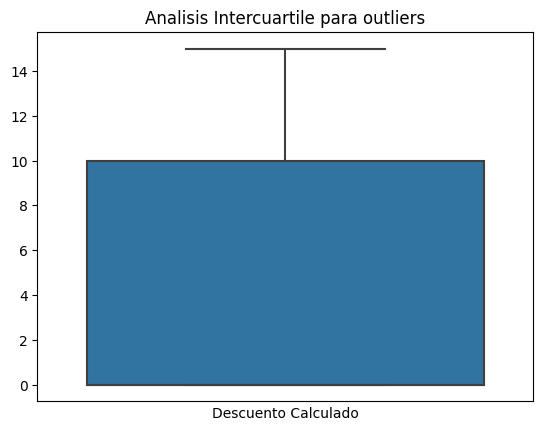

In [23]:
analisisInterquartile(orders,'precio_unitario_calculado','Analisis Intercuartile para outliers','Precio Unitario Calculado')
analisisInterquartile(orders,'cantidad_calculada','Analisis Intercuartile para outliers','Cantidad Calculada')
analisisInterquartile(orders,'descuento_calculado','Analisis Intercuartile para outliers','Descuento Calculado')

Ya con el Metodo intercuartil pasamos a Nan los outliers para despues eliminarlos y setearlos en nuestras columnas originales

In [24]:
def outliersIQR(df,col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3-Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    df.loc[((df[col]<=limite_inferior) | (df[col]>=limite_superior)), col]= np.NaN
outliersIQR(orders,'cantidad_calculada')
outliersIQR(orders,'descuento_calculado')

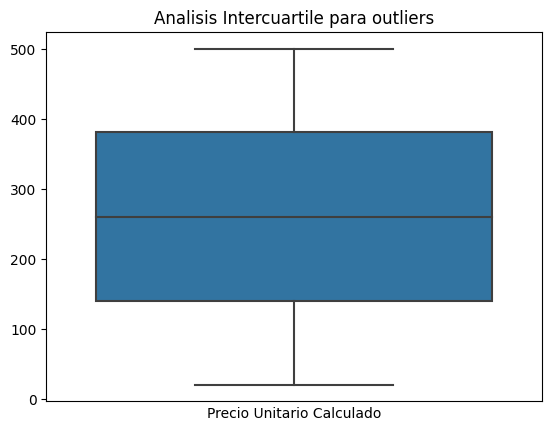

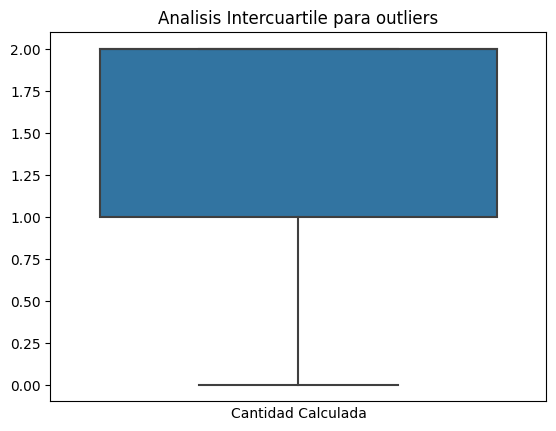

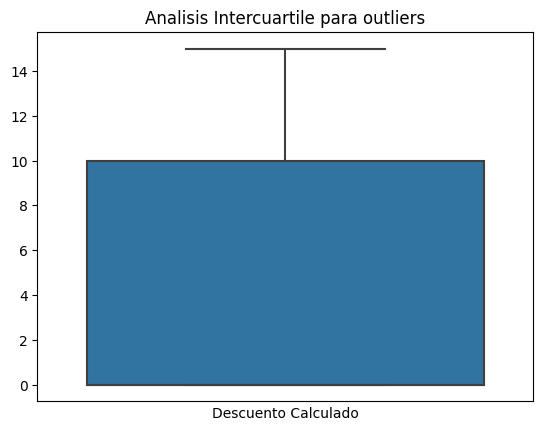

In [25]:
analisisInterquartile(orders,'precio_unitario_calculado','Analisis Intercuartile para outliers','Precio Unitario Calculado')
analisisInterquartile(orders,'cantidad_calculada','Analisis Intercuartile para outliers','Cantidad Calculada')
analisisInterquartile(orders,'descuento_calculado','Analisis Intercuartile para outliers','Descuento Calculado')

In [26]:
orders['precio_unitario'] = orders['precio_unitario'].fillna(orders['precio_unitario_calculado'])
orders['cantidad'] = orders['cantidad'].fillna(orders['cantidad_calculada'])
orders['monto_descuento'] = orders['monto_descuento'].fillna(orders['descuento_calculado'])

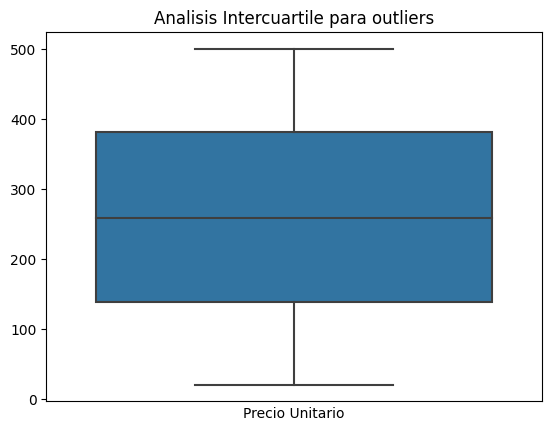

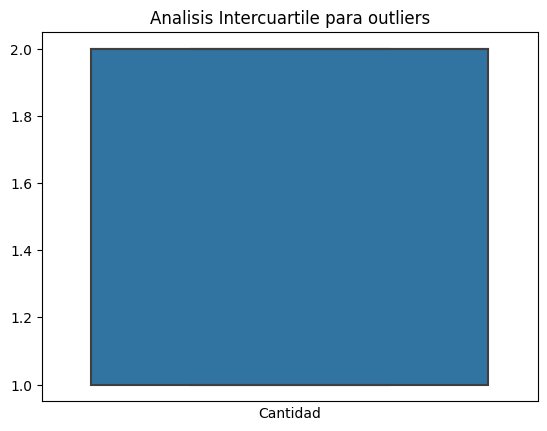

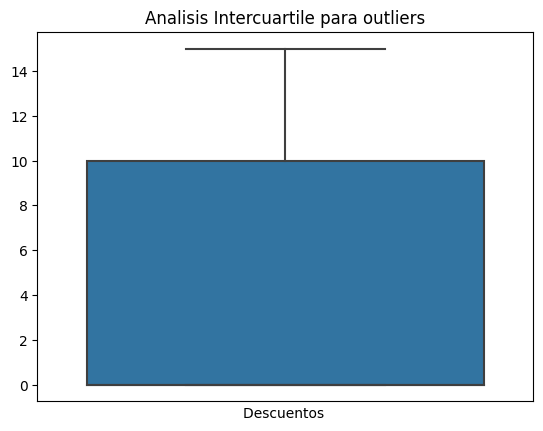

In [27]:
analisisInterquartile(orders,'precio_unitario','Analisis Intercuartile para outliers','Precio Unitario')
analisisInterquartile(orders,'cantidad','Analisis Intercuartile para outliers','Cantidad')
analisisInterquartile(orders,'monto_descuento','Analisis Intercuartile para outliers','Descuentos ')

In [28]:
print("cantidad de nulos en orders desglosado: ", orders.isna().sum())
print("cantidad de nulos en catalog desglosado: ", catalog.isna().sum())
print("cantidad de nulos en marketing desglosado: ", marketing.isna().sum())


cantidad de nulos en orders desglosado:  id_pedido                    0
id_usuario                   0
fecha_hora_pedido            0
pais                         0
dispositivo                  0
fuente_referencia            0
nombre_producto              0
categoria_producto           0
cantidad                     0
precio_unitario              0
monto_descuento              0
monto_total                  0
descuento_calculado          0
cantidad_calculada           0
precio_unitario_calculado    0
dtype: int64
cantidad de nulos en catalog desglosado:  nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64
cantidad de nulos en marketing desglosado:  fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64


In [29]:
orders = orders.drop(columns=["descuento_calculado",'cantidad_calculada','precio_unitario_calculado'])

In [30]:
orders[orders.duplicated(subset=['id_pedido','id_usuario','fecha_hora_pedido'], keep=False)]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
680,order_734,user_6347,2025-05-02,Colombia,desktop,organic,Blender-XL-Red,Hogar,1.0,58.00,0.0,58.00
758,order_812,user_1530,2025-03-31,Argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32
920,order_974,user_3262,2025-05-04,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16
1307,order_1361,user_507,2025-06-27,Mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,2.0,239.61,0.0,479.22
1681,order_1735,user_728,2025-05-13,Mexico,mobile,social,Tablet-Standard-64GB,Electronica,2.0,419.04,0.0,838.08
...,...,...,...,...,...,...,...,...,...,...,...,...
25031,order_3913,user_380,2025-02-18,Argentina,desktop,paid_search,Phone-Pro-128GB,Electronica,1.0,82.28,0.0,82.28
25032,order_23405,user_7833,2025-04-04,Colombia,mobile,paid_search,Phone-Pro-128GB,Electronica,2.0,99.25,5.0,193.50
25033,order_5615,user_5417,2025-05-13,Colombia,desktop,social,Blender-XL-Red,Hogar,2.0,450.35,5.0,895.69
25034,order_812,user_1530,2025-03-31,Argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32


In [31]:
orders = orders.drop_duplicates(subset=['id_pedido','id_usuario', 'fecha_hora_pedido'], keep='first')

In [32]:
orders.shape

(24936, 12)

In [33]:
fillNaCategorico(marketing,'canal')

<AxesSubplot:>

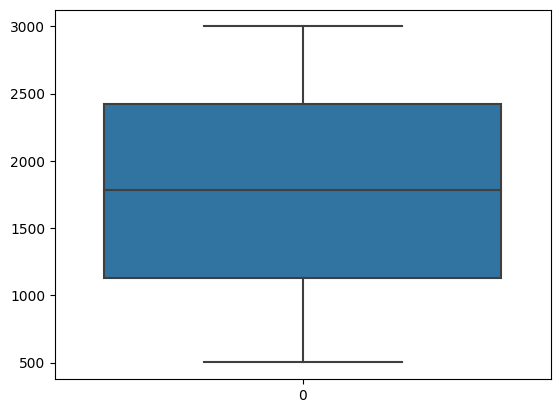

In [34]:
sns.boxplot(data=marketing['gasto'])

In [35]:
marketing[marketing.duplicated(subset=['id_campaña','pais','fecha'], keep=False)]

,fecha,pais,id_campaña,canal,gasto


In [36]:
marketing[marketing.duplicated(subset=['pais','fecha'], keep=False)]

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40
...,...,...,...,...,...
1615,2025-06-29,Colombia,paid_search_Colombia,paid_search,550.50
1616,2025-06-29,Colombia,social_Colombia,social,999.15
1617,2025-06-29,Argentina,organic_Argentina,organic,1267.14
1618,2025-06-29,Argentina,paid_search_Argentina,paid_search,2719.41


no son duplicados extraños ya que todos estan ligados a un ID diferente

In [37]:
print("cantidad de nulos en orders desglosado: ", orders.isna().sum())
print("cantidad de nulos en catalog desglosado: ", catalog.isna().sum())
print("cantidad de nulos en marketing desglosado: ", marketing.isna().sum())


cantidad de nulos en orders desglosado:  id_pedido             0
id_usuario            0
fecha_hora_pedido     0
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
cantidad              0
precio_unitario       0
monto_descuento       0
monto_total           0
dtype: int64
cantidad de nulos en catalog desglosado:  nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64
cantidad de nulos en marketing desglosado:  fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64


In [38]:
orders['categoria_producto'] = orders['categoria_producto'].str.replace(
    'Electronica', 'Electrónica'
)
catalog['categoria_producto'] = catalog['categoria_producto'].str.replace(
    'Electronica', 'Electrónica'
)

---
Una vez finalizada la limpieza, exportamos los datasets para utilizarlos en el analizis futuro.

In [39]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales


In [40]:
# tu código aquí
ingreso_total = orders['monto_total'].sum()

In [41]:
left_cols = ['nombre_producto','categoria_producto','cantidad','monto_total']
right_cols = ['nombre_producto','categoria_producto','costo_unitario']
orders_small = orders[left_cols].copy()
catalog_small = catalog[right_cols].copy()
merged = pd.merge(orders_small,catalog_small, on =['nombre_producto','categoria_producto'],how = 'inner')
merged['costo_final'] = merged['costo_unitario'] * merged['cantidad']
merged.head(5)
costo_total =merged['costo_final'].sum()

In [42]:
producto_mas_vendido = orders['nombre_producto'].describe().top

In [43]:
inversion_total = marketing['gasto'].sum()

In [44]:
margen_bruto = ingreso_total - costo_total

In [45]:
ganancia_neta_operativa = ingreso_total - (costo_total + inversion_total)

In [46]:
print("Rentabilidad del Negocio")
print("Ingreso Total:", ingreso_total)
print("Costo Total:", costo_total)
print("Inversion Total en Marketing:", inversion_total)
print("Margen Bruto:", margen_bruto)
print("Ganancia Neta Operativa:", ganancia_neta_operativa)
print("Margen bruto porcentual", (margen_bruto/ingreso_total)*100)
print("Margen operativo porcentual:", (ganancia_neta_operativa/ingreso_total)*100)
print("ROAS:", (inversion_total/ingreso_total)*100)

Rentabilidad del Negocio
Ingreso Total: 9622281.56
Costo Total: 3829616.01
Inversion Total en Marketing: 2871843.53
Margen Bruto: 5792665.550000001
Ganancia Neta Operativa: 2920822.0200000014
Margen bruto porcentual 60.20054094114453
Margen operativo porcentual: 30.354776066228528
ROAS: 29.845764874916004


El negocio si es rentable estamos teniendo buenos numeros recuperando arriba de la mitad en cuanto a costos vs ingresos, por cada 100 gastados estamos recuperando el 60% que despues de pagar marketing nos quedamos con 30% neto de ganancia de la empresa.
tambien marketing esta aportando un 29% es un area de oportunidad que se puede analisar a profundidad para incrementar la participacion y tener mas alcance a nuevos clientes

In [47]:
ticket_promedio = orders['monto_total'].mean()
cantidad_de_productos_promedio = orders['cantidad'].mean().round()

In [48]:
print("Comportamiento de las ventas")
print("Ticket promedio:",ticket_promedio)
print("Cantidad promedio de producto por orden:", cantidad_de_productos_promedio)
print("Producto mas vendido:", producto_mas_vendido)
marketing_chanels = marketing.groupby('canal',as_index=False).sum()
marketing_chanels

Comportamiento de las ventas
Ticket promedio: 385.87911292909854
Cantidad promedio de producto por orden: 2.0
Producto mas vendido: Vacuum-Pro-Black


,canal,gasto
0,organic,913533.01
1,paid_search,1040267.31
2,social,918043.21


In [49]:
orders_chanels= orders.groupby("fuente_referencia",as_index=False).sum()
orders_chanels.rename(columns={"fuente_referencia": "canal"},inplace=True)
orders_chanels

,canal,cantidad,precio_unitario,monto_descuento,monto_total
0,organic,12464.0,2127899.30,37385.0,3178228.55
1,paid_search,12409.0,2163843.72,37165.0,3209280.07
2,social,12654.0,2175729.81,37770.0,3234772.94


In [50]:
left_cols = ['canal','monto_total']
right_cols = ['canal','gasto']
orders_chanels_small = orders_chanels[left_cols].copy()
chanels_small = marketing_chanels[right_cols].copy()
merged_marketing = pd.merge(orders_chanels_small,chanels_small, on =['canal'],how = 'inner')

merged_marketing.head()
merged_marketing['profit_Porcentual'] = ((merged_marketing['monto_total'] - merged_marketing['gasto']) /ingreso_total) *100
merged_marketing

,canal,monto_total,gasto,profit_Porcentual
0,organic,3178228.55,913533.01,23.535952
1,paid_search,3209280.07,1040267.31,22.541564
2,social,3234772.94,918043.21,24.076719


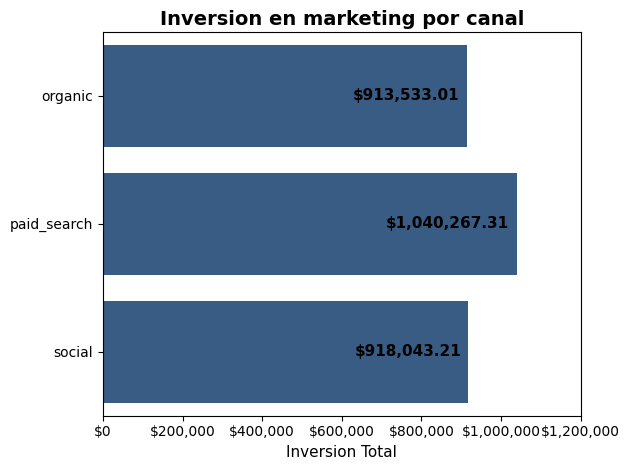

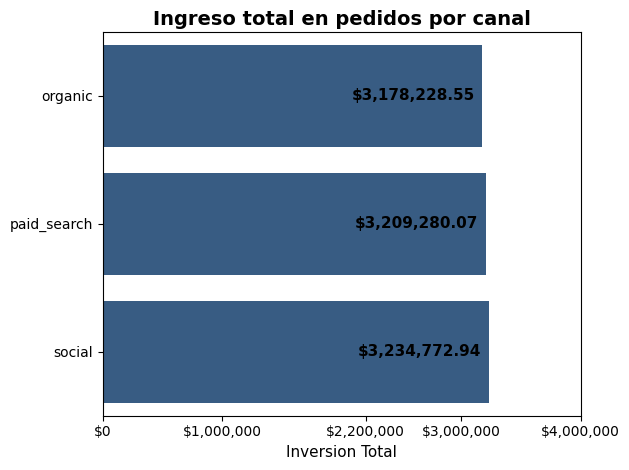

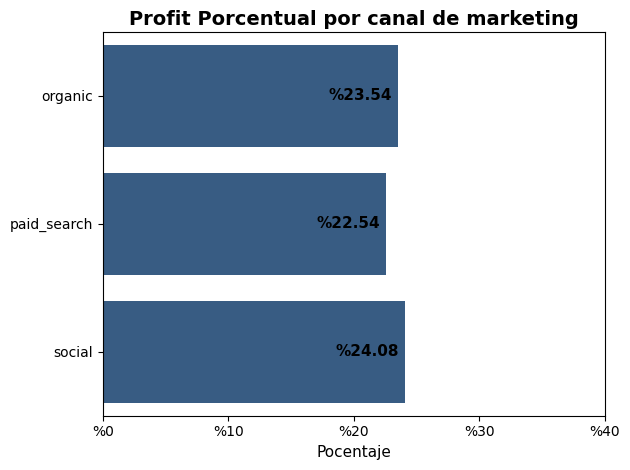

In [51]:
ax = sns.barplot(data=marketing_chanels, x='gasto', y='canal', color='#2b5c8f')

plt.title('Inversion en marketing por canal', fontsize=14, fontweight='bold', pad=5)
plt.xlabel('Inversion Total', fontsize=11)
plt.ylabel('', fontsize=11)

for p in ax.patches:
    width = p.get_width()
    
    x_pos = width * 0.98  
    y_pos = p.get_y() + p.get_height() / 2.
    label_text = f'${width:,.2f}'
    
    ax.annotate(
        label_text,
        (x_pos, y_pos),
        ha='right', 
        va='center',
        xytext=(0, 0), 
        textcoords='offset points',
        fontsize=11,
        fontweight='bold',
        bbox=None 
    )
    
max_val = 1040267.31
plt.xlim(0, max_val * 1.05) 

tick_values = [0, 200000, 400000, 600000, 800000, 1000000, 1200000]
ax.set_xticks(tick_values)
ax.set_xticklabels([f'${v:,.0f}' for v in tick_values], rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

ax = sns.barplot(data=orders_chanels, x='monto_total', y='canal', color='#2b5c8f')

plt.title('Ingreso total en pedidos por canal', fontsize=14, fontweight='bold', pad=5)
plt.xlabel('Inversion Total', fontsize=11)
plt.ylabel('', fontsize=11)

for p in ax.patches:
    width = p.get_width()
    
    x_pos = width * 0.98  
    y_pos = p.get_y() + p.get_height() / 2.
    label_text = f'${width:,.2f}'
    
    ax.annotate(
        label_text,
        (x_pos, y_pos),
        ha='right', 
        va='center',
        xytext=(0, 0), 
        textcoords='offset points',
        fontsize=11,
        fontweight='bold',
        bbox=None 
    )
    
max_val = 1040267.31
plt.xlim(0, max_val * 1.05) 

tick_values = [0,  1000000, 2200000, 3000000, 4000000]
ax.set_xticks(tick_values)
ax.set_xticklabels([f'${v:,.0f}' for v in tick_values], rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

ax = sns.barplot(data=merged_marketing, x='profit_Porcentual', y='canal', color='#2b5c8f')

plt.title('Profit Porcentual por canal de marketing', fontsize=14, fontweight='bold', pad=5)
plt.xlabel('Pocentaje', fontsize=11)
plt.ylabel('', fontsize=11)

for p in ax.patches:
    width = p.get_width()
    
    x_pos = width * 0.98  
    y_pos = p.get_y() + p.get_height() / 2.
    label_text = f'%{width:,.2f}'
    
    ax.annotate(
        label_text,
        (x_pos, y_pos),
        ha='right', 
        va='center',
        xytext=(0, 0), 
        textcoords='offset points',
        fontsize=11,
        fontweight='bold',
        bbox=None 
    )
    
max_val = 25.31
plt.xlim(0, max_val * 1.05) 

tick_values = [0,  10, 20, 30, 40]
ax.set_xticks(tick_values)
ax.set_xticklabels([f'%{v:,.0f}' for v in tick_values], rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

Como pudimos observar en los graficos hemos invertido bastante en nuestras campañas de paid search con un total de $1,040,267.31 y al momento de compararlas con el profit que cada canal genero fue la que mas se quedo atras Siendo el canal social el que mas genero y es el segundo en mas inversion. propongo hacer una investigacion de en que esta fallando paid search tal vez no tiene la demografia correcta y no le llega a clientes potenciales y redirijir parte de su inversion hacia social y organic para mejor desempeño general

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

In [52]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [53]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [54]:
events['nombre_evento'].value_counts()

first_visit         29957
add_to_cart         24157
select_item         23887
begin_checkout      17971
add_payment_info    12018
purchase            12010
Name: nombre_evento, dtype: int64

In [55]:
events['timestamp_evento'] = pd.to_datetime(events['timestamp_evento'],errors="coerce")

In [56]:
events['timestamp_evento'].describe()

count                  120000
unique                    181
top       2025-06-11 00:00:00
freq                      741
first     2025-01-01 00:00:00
last      2025-06-30 00:00:00
Name: timestamp_evento, dtype: object

In [57]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
WITH first_visit AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
),
add_to_cart AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart' 
),
select_item AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item' 
),
begin_checkout AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout' 
),
add_payment_info AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
purchase AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
    )
SELECT
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(atc.id_usuario) AS usuarios_add_to_cart,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(bc.id_usuario) AS usuarios_begin_check_out,
    COUNT(api.id_usuario) AS usuarios_add_payment,
    COUNT(p.id_usuario) AS usuarios_purchase
FROM first_visit AS fv
    LEFT JOIN add_to_cart AS atc
    ON atc.id_usuario = fv.id_usuario
    LEFT JOIN select_item AS si
    ON si.id_usuario = fv.id_usuario
    LEFT JOIN begin_checkout AS bc
    ON bc.id_usuario = fv.id_usuario
    LEFT JOIN add_payment_info AS api
    ON api.id_usuario = fv.id_usuario
    LEFT JOIN purchase AS p
    ON p.id_usuario = fv.id_usuario
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,usuarios_first_visit,usuarios_add_to_cart,usuarios_select_item,usuarios_begin_check_out,usuarios_add_payment,usuarios_purchase
0,7796,7439,7393,7031,6088,6068


In [58]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH first_visit AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
),
add_to_cart AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart' 
),
select_item AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item' 
),
begin_checkout AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout' 
),
add_payment_info AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
purchase AS(
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
    ),
funnel_counts AS (
SELECT
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(atc.id_usuario) AS usuarios_add_to_cart,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(bc.id_usuario) AS usuarios_begin_check_out,
    COUNT(api.id_usuario) AS usuarios_add_payment,
    COUNT(p.id_usuario) AS usuarios_purchase
FROM first_visit AS fv
    LEFT JOIN add_to_cart AS atc
    ON atc.id_usuario = fv.id_usuario
    LEFT JOIN select_item AS si
    ON si.id_usuario = fv.id_usuario
    LEFT JOIN begin_checkout AS bc
    ON bc.id_usuario = fv.id_usuario
    LEFT JOIN add_payment_info AS api
    ON api.id_usuario = fv.id_usuario
    LEFT JOIN purchase AS p
    ON p.id_usuario = fv.id_usuario)

SELECT
ROUND((usuarios_add_to_cart * 100) / NULLIF (usuarios_first_visit,0),2) AS conversion_add_to_cart,
ROUND((usuarios_select_item * 100) / NULLIF (usuarios_first_visit,0),2) AS conversion_select_item,
ROUND((usuarios_begin_check_out * 100) / NULLIF (usuarios_first_visit,0),2) AS conversion_begin_checkout,
ROUND((usuarios_add_payment * 100) / NULLIF (usuarios_first_visit,0),2) AS conversion_add_payment_info,
ROUND((usuarios_purchase * 100) / NULLIF (usuarios_first_visit,0),2) AS conversion_purchase
FROM funnel_counts
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,conversion_add_to_cart,conversion_select_item,conversion_begin_checkout,conversion_add_payment_info,conversion_purchase
0,95.0,94.0,90.0,78.0,77.0


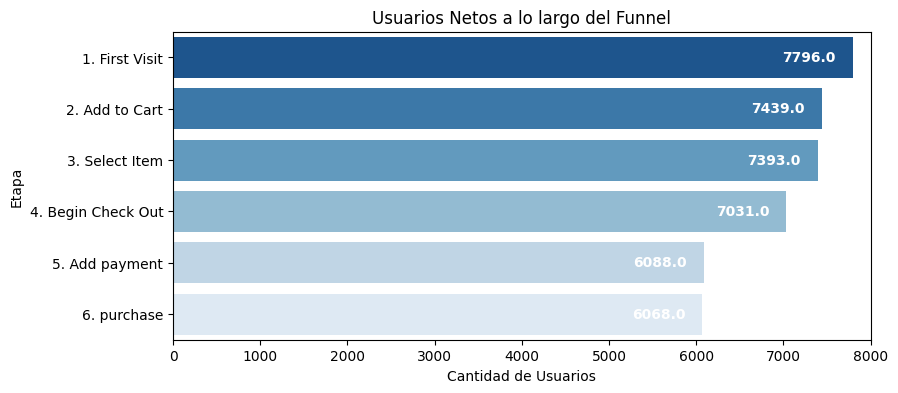

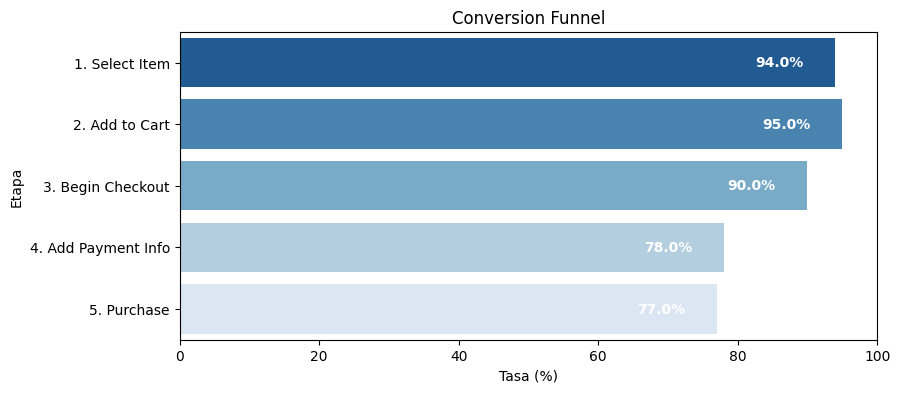

In [59]:
datos = pd.DataFrame({
    'Etapa': ['1. First Visit', '2. Add to Cart', '3. Select Item', '4. Begin Check Out', '5. Add payment', '6. purchase'],
    'Cantidad de Usuarios': [7796, 7439, 7393, 7031, 6088, 6068] 
})

plt.figure(figsize=(9, 4))
ax = sns.barplot(data=datos, x='Cantidad de Usuarios', y='Etapa', palette='Blues_r')

for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}', 
                (p.get_width() - 500, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', color='white', fontweight='bold')

plt.title('Usuarios Netos a lo largo del Funnel')
plt.xlim(0, 8000)
plt.show()

datos = pd.DataFrame({
    'Etapa': ['1. Select Item', '2. Add to Cart', '3. Begin Checkout', '4. Add Payment Info', '5. Purchase'],
    'Tasa (%)': [94.0, 95.0, 90.0, 78.0, 77.0]
})

plt.figure(figsize=(9, 4))
ax = sns.barplot(data=datos, x='Tasa (%)', y='Etapa', palette='Blues_r')

# Agregar los valores numéricos sobre las barras
for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%', 
                (p.get_width() - 8, p.get_y() + p.get_height() / 2.),
                ha='center', va='center', color='white', fontweight='bold')

plt.title('Conversion Funnel')
plt.xlim(0, 100)
plt.show()

Como podemos observar en las graficas mantenemos un buen flujo de usuarios y conversion en nuestras primeras etapas, pero nos desplomamos al llegar a payment info.
Propongo realizar una junta con UI para realizar un experimento y analizar si cambiando ciertos aspectos de nuestro formulario ayuda a que los usuario puedan completar su compra y poder aumentar el numero neto de usuarios y la conversion de payment info to purchase

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)


In [60]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [61]:
users['fecha_registro'].describe()

count           8000
unique           151
top       2025-01-24
freq              72
Name: fecha_registro, dtype: object

In [62]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT * 
FROM user_activity
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [63]:
user_activity['fecha_actividad'].describe()

count          32000
unique           172
top       2025-02-11
freq             245
Name: fecha_actividad, dtype: object

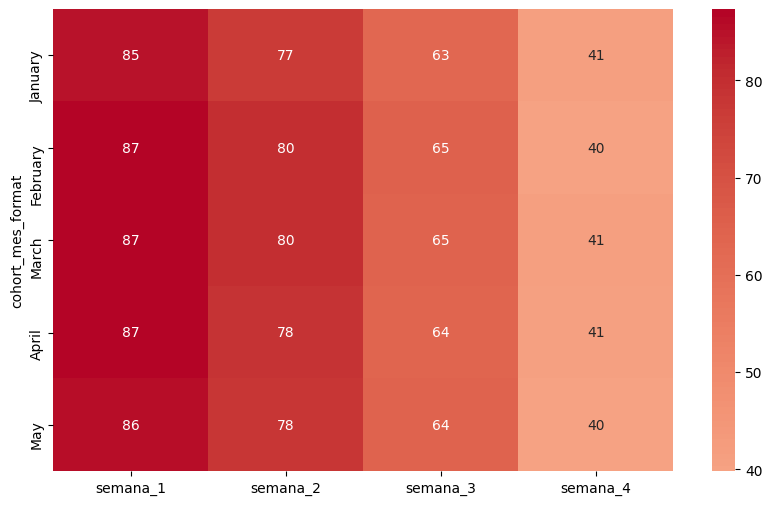

In [64]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cohort AS (
    SELECT
        id_usuario,
        TO_CHAR(DATE_TRUNC('month', fecha_registro::DATE), 'YYYY-MM') AS cohort
    FROM users
),
activity AS (
    SELECT
        c.id_usuario,
        c.cohort,
        ua.dias_despues_registro,
        ua.activo
    FROM cohort AS c
    LEFT JOIN user_activity AS ua 
        ON c.id_usuario = ua.id_usuario
)
SELECT
    cohort,
    ROUND(
        (COUNT(DISTINCT CASE WHEN dias_despues_registro >= 7 AND activo = 1 THEN id_usuario END) * 100.0) 
        / NULLIF(COUNT(DISTINCT id_usuario), 0), 1
    ) AS semana_1,
    ROUND(
        (COUNT(DISTINCT CASE WHEN dias_despues_registro >= 14 AND activo = 1 THEN id_usuario END) * 100.0) 
        / NULLIF(COUNT(DISTINCT id_usuario), 0), 1
    ) AS semana_2,
    ROUND(
        (COUNT(DISTINCT CASE WHEN dias_despues_registro >= 21 AND activo = 1 THEN id_usuario END) * 100.0) 
        / NULLIF(COUNT(DISTINCT id_usuario), 0), 1
    ) AS semana_3,
    ROUND(
        (COUNT(DISTINCT CASE WHEN dias_despues_registro >= 28 AND activo = 1 THEN id_usuario END) * 100.0) 
        / NULLIF(COUNT(DISTINCT id_usuario), 0), 1
    ) AS semana_4
FROM activity
GROUP BY cohort
ORDER BY cohort;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final['cohort']  = cohorte_final['cohort'] = pd.to_datetime(cohorte_final['cohort'],errors="coerce")
cohorte_final['cohort'].describe()
cohorte_final['cohort_mes_format'] = cohorte_final['cohort'].dt.month_name()
cohorte_final
cohorte_final_heatmap = cohorte_final.set_index('cohort_mes_format')
plt.figure(figsize=(10,6))
sns.heatmap(cohorte_final_heatmap.drop(columns=['cohort']), annot= True, cmap="coolwarm", center=0)
plt.show()

como podemos observar en nuestro heatmap cada inicio de mes empezamos muy bien con una buena recepcion de clientes y decrese de manera regular pero para la cuarta semana decrese casi en 25 usuarios lo cual me hace pensar que podriamos hacer campañas de fin de mes para impulsar algunas ventas y disminuir el numero de clientes que ya no vuelven

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** La tasa de conversion se igual en ambas paginas Cualquier diferencia se debe al azar del muestreo
   - **H₁ (Hipótesis alternativa):** La taza de conversion es diferente entre ambas paginas hay un factor que influye en la decision de compra
   
**Test estadístico:** ...  
**Nivel de significancia alpha:** ...

In [65]:
# tu código aquí
experiment_ui = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

In [66]:
experiment_ui.head(5)
print(experiment_ui.shape)

(10000, 7)


In [67]:
from statsmodels.stats.proportion import proportions_ztest
conversiones = experiment_ui[experiment_ui['convirtio']== 1].groupby('variante')['convirtio'].sum()
totales = experiment_ui.groupby('variante')['convirtio'].count()

conteos = [conversiones['control'],conversiones['tratamiento']]
num_observaciones = [totales['control'],totales['tratamiento']]

print(conversiones)
print(totales)

print(f"Exitos: {conteos}")
print(f"Totales:{num_observaciones}")

z_stat, p_value = proportions_ztest(conteos,num_observaciones)
print(f"Estadistico z: {z_stat}")
print(f"Valor P: {p_value}")

alpha = 0.05

if p_value < alpha:
    print("No rechazamos la hipotesis nula")
else:
    print("Rechazamos la hipotesis nula")

tasa_control = conteos[0] / num_observaciones[0]
tasa_tratamiento = conteos[1] / num_observaciones[1]
print(f"Tasa de conversion de Pagina de control: {tasa_control:.2%}")
print(f"Tasa de conversion de Pagina de tratamiento: {tasa_tratamiento:.2%}")

variante
control        779
tratamiento    820
Name: convirtio, dtype: int64
variante
control        4965
tratamiento    5035
Name: convirtio, dtype: int64
Exitos: [779, 820]
Totales:[4965, 5035]
Estadistico z: -0.8132782986429474
Valor P: 0.41605851639119995
Rechazamos la hipotesis nula
Tasa de conversion de Pagina de control: 15.69%
Tasa de conversion de Pagina de tratamiento: 16.29%


al realizar el z test podemos ver que si hay una diferencia entre una pagina y otra rechazando la hipotesis nula el siguiente paso que propongo es un sondeo por en cuesta de que les gusto de la pagina de tratamiento para decidir si lo replicamos en otros pasos del funnel o mejorar aun mas la pagina de begin checkout

---

https://drive.google.com/drive/folders/1EWevc8YBaw9SsF84hn5u_s3IITDP7mLA?usp=sharing
